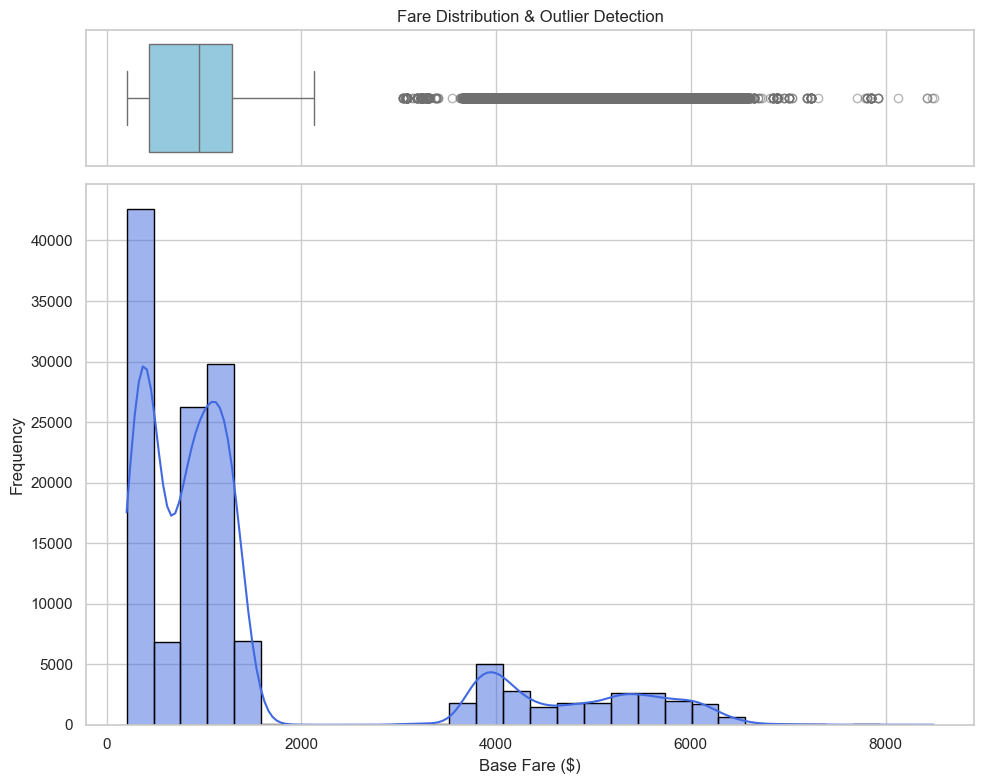

--- Statistical Summary ---
25th Percentile (Q1): $440.00
75th Percentile (Q3): $1283.20
Interquartile Range (IQR): $843.20
Lower Outlier Threshold: < $-824.80
Upper Outlier Threshold: > $2548.00


In [5]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('airlines_flights_data.csv')
df_vistara = df[df['airline'] == 'Vistara'].copy()

#Creating sales_channel:
df_vistara["sales_channel"] = 'Direct'
df_vistara

#Selecting a sample of 7% of data, assign channels with 80/20 split, and append back into dataframe:
#Random number generator
rng = np.random.default_rng(seed=42)

#Selecting 7% of rows
sample = int(len(df_vistara) * 0.07)
sample_rows = rng.choice(df_vistara.index, size=sample, replace=False)
df_sample = df_vistara.loc[sample_rows].copy()

#Assign GDS/OTA sales channels to sample:
sample_channels = rng.choice(['GDS', 'OTA'], size=len(df_sample), p=[0.8, 0.2])
df_sample['sales_channel'] = sample_channels

#Adding to the end of df_vistara
df_vistara = pd.concat([df_vistara, df_sample], ignore_index=True)

##Booking Class:
##Creating windows for booking class tiers in economy and business:
bk_cl_cond = [
    (df_vistara["days_left"] >=0) & (df_vistara["days_left"] <= 7) & (df_vistara["class"] == "Economy"),
    (df_vistara["days_left"] > 7) & (df_vistara["days_left"] <= 42) & (df_vistara["class"] == "Economy"),
    (df_vistara["days_left"] > 42) & (df_vistara["class"] == "Economy"),
    (df_vistara["days_left"] >=0) & (df_vistara["days_left"] <= 7) & (df_vistara["class"] == "Business"),
    (df_vistara["days_left"] > 7) & (df_vistara["days_left"] <= 42) & (df_vistara["class"] == "Business"),
    (df_vistara["days_left"] > 42) & (df_vistara["class"] == "Business")
]

bk_cl = ["F", "H", "K", "M", "Q", "T"]

#Create new column:
df_vistara["booking_class"] = np.select(bk_cl_cond, bk_cl, default="X")

#Injecting 23% GDS booking class code noncompliance:
percentage = 0.23
gds_selected = df_vistara.loc[df_vistara["sales_channel"].isin(['GDS', 'OTA'])].sample(
    frac=percentage, random_state=rng).index
df_vistara.loc[gds_selected, "booking_class"] = rng.choice(
    bk_cl, size=len(gds_selected)
)

##Creating base_fare to then develop a dynamic pricing structure:
##Early morning and late night flights are cheaper than others, layovers are cheaper,
##shorter flights are cheaper

#Setting baseline ticket fare
df_vistara["price"] = 150
df_vistara["price"] = df_vistara["price"].astype(float)

#Departure Time dynamic pricing:

##Duration & stops dynamic pricing:
short_z_stops_add = (df_vistara["stops"] == "zero") & (df_vistara["duration"] <= 14.27)
long_z_stops_add = (df_vistara["stops"] == "zero") & (df_vistara["duration"] > 14.27)
df_vistara.loc[short_z_stops_add, "price"] += df_vistara.loc[short_z_stops_add, "duration"] * 30
df_vistara.loc[long_z_stops_add, "price"] += df_vistara.loc[long_z_stops_add, "duration"] * 50
df_vistara

##one stop -- $20 per hour for short, $40 per hour for long
short_o_stops_add = (df_vistara["stops"] == "one") & (df_vistara["duration"] <= 14.27)
long_o_stops_add = (df_vistara["stops"] == "one") & (df_vistara["duration"] > 14.27)
df_vistara.loc[short_o_stops_add, "price"] += df_vistara.loc[short_o_stops_add, "duration"] * 20
df_vistara.loc[long_o_stops_add, "price"] += df_vistara.loc[long_o_stops_add, "duration"] * 40

##two or more -- 10 per hour for short, $30 per hour for long
short_t_stops_add = (df_vistara["stops"] == "two_or_more") & (df_vistara["duration"] <= 14.27)
long_t_stops_add = (df_vistara["stops"] == "two_or_more") & (df_vistara["duration"] > 14.27)
df_vistara.loc[short_t_stops_add, "price"] += df_vistara.loc[short_t_stops_add, "duration"] * 10
df_vistara.loc[long_t_stops_add, "price"] += df_vistara.loc[long_t_stops_add, "duration"] * 30
df_vistara

##Business premium: business is 3x more expensive on average flights, 5x more on long-haul
business_short = (df_vistara["class"] == "Business") & (df_vistara["duration"] <= 14.27)
business_long = (df_vistara["class"] == "Business") & (df_vistara["duration"] > 14.27)
df_vistara.loc[business_short, "price"] *= 3
df_vistara.loc[business_long, "price"] *= 5

##Booking Class: create windows for booking class tiers in economy and business
class_adj = {"F": 100, "H": 50 , "K": 25, "M": 160, "Q": 80, "T": 40}
mask = df_vistara["booking_class"].isin(class_adj.keys())
df_vistara.loc[mask, "price"] += df_vistara["booking_class"].map(class_adj)

##Fare standardization complete! Renaming price to base_fare
df_vistara = df_vistara.rename(columns={"price": "base_fare"})

##Fare distribution (to determine low vs. mid vs. premium tier volume)
sns.set_theme(style='whitegrid')
fig, (ax_box, ax_hist) = plt.subplots (
    2, 1, figsize=(10, 8), sharex=True, gridspec_kw={'height_ratios': [0.2, 0.8]})

sns.boxplot(
    x=df_vistara['base_fare'],
    ax=ax_box,
    color='skyblue',
    flierprops={'marker': 'o', 'color': 'red', 'alpha': 0.5},
)
ax_box.set(xlabel='', title='Fare Distribution & Outlier Detection')

sns.histplot(
    df_vistara['base_fare'],
    ax=ax_hist,
    kde=True,
    color='royalblue',
    bins=30,
    edgecolor='black',
)
ax_hist.set_xlabel('Base Fare ($)', fontsize=12)
ax_hist.set_ylabel('Frequency', fontsize=12)

plt.tight_layout()
plt.show()

Q1 = df_vistara['base_fare'].quantile(0.25)
Q3 = df_vistara['base_fare'].quantile(0.75)

IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f'--- Statistical Summary ---')
print(f'25th Percentile (Q1): ${Q1:.2f}')
print(f'75th Percentile (Q3): ${Q3:.2f}')
print(f'Interquartile Range (IQR): ${IQR:.2f}')
print(f'Lower Outlier Threshold: < ${lower_bound:.2f}')
print(f'Upper Outlier Threshold: > ${upper_bound:.2f}')

##25th Percentile (Q1): $440.00
##75th Percentile (Q3): $1281.70

##Assign tax/fees adjustments accordi
price_tiers = [
    (df_vistara["base_fare"] >= 0) & (df_vistara["days_left"] <= 440.00),
    (df_vistara["base_fare"] > 440.00) & (df_vistara["days_left"] <= 1281.70),
    (df_vistara["base_fare"] >= 1281.70)
]

tier_calc = [
    df_vistara["base_fare"] * 0.25,
    df_vistara["base_fare"] * 0.175,
    df_vistara["base_fare"] * 0.1,
]

#Create new column tax_fees:
df_vistara["tax_fees"] = np.select(price_tiers, tier_calc, default="X")
df_vistara["tax_fees"] = pd.to_numeric(df_vistara["tax_fees"], errors="coerce")
df_vistara["tax_fees"] = df_vistara["tax_fees"].round(2)

#Create new column total_fare:
df_vistara["total_fare"] = df_vistara["base_fare"] + df_vistara["tax_fees"]
df_vistara.to_csv('vistara_data.csv')